In [1]:
# Imports

# Standard library
from collections import defaultdict
from pathlib import Path
import textwrap

# Data and visualization
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

# RDKit
from rdkit import Chem
from rdkit.Chem import Draw, rdDepictor, rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold

# Scikit-learn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    ConfusionMatrixDisplay,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F

# PyTorch Geometric
from torch_geometric.datasets import MoleculeNet
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GINEConv, global_mean_pool
from torch_geometric.utils.smiles import e_map, x_map

/Users/nasir.degu/Desktop/eng2440-a3/.venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
DATA_ROOT = Path("data/MoleculeNet")

dataset = MoleculeNet(
    root=str(DATA_ROOT),
    name="BBBP"
)

print(dataset)
print("Number of molecules:", len(dataset))
print("First graph:", dataset[0])

raw_count = len(pd.read_csv(dataset.raw_paths[0]))

print()
print("Raw BBBP records:", raw_count)
print("Records not retained by PyG:", raw_count - len(dataset))

BBBP(2039)
Number of molecules: 2039
First graph: Data(x=[20, 9], edge_index=[2, 40], edge_attr=[40, 3], smiles='[Cl].CC(C)NCC(O)COc1cccc2ccccc12', y=[1, 1])

Raw BBBP records: 2050
Records not retained by PyG: 11


### Explanation

The original BBBP dataset contains **2,050 molecules**, represented by SMILES strings. PyTorch Geometric (PyG) uses RDKit to convert these strings into molecular graphs.

However, PyG retained only **2,039 molecular graphs**, meaning that **11 records were excluded during dataset processing**.

As a result, **2,050 − 11 = 2,039 molecules** were successfully loaded.

In [3]:
graph = dataset[0]

print("Node-feature shape:", graph.x.shape)
print("Edge-index shape:", graph.edge_index.shape)
print("Edge-feature shape:", graph.edge_attr.shape)
print("Label:", graph.y)
print("SMILES:", graph.smiles)

Node-feature shape: torch.Size([20, 9])
Edge-index shape: torch.Size([2, 40])
Edge-feature shape: torch.Size([40, 3])
Label: tensor([[1.]])
SMILES: [Cl].CC(C)NCC(O)COc1cccc2ccccc12


### Task A - Part 1 (State the input, output, unit of analysis and intended technical use.
### Explain what the positive and negative labels mean.)

**Input:** A molecule represented as a graph, where atoms are nodes and chemical bonds are edges, with categorical features describing each atom and bond.

**Output:** A predicted probability between 0 and 1 that the molecule is BBB-penetrating (class 1). A classification threshold is then used to assign a binary label.

**Unit of analysis:** One molecule.

**Intended technical use:** Predicting blood-brain barrier permeability from molecular structure to help screen candidate compounds during drug discovery.

**Labels:**
- **1 (Positive):** The molecule is classified as BBB-penetrating.
- **0 (Negative):** The molecule is classified as Non-BBB-penetrating.

In [4]:
### Task A - Part 2 (Report dataset size, missing or non-finite labels, invalid or empty molecular graphs, class counts and class proportions.)

labels = np.array([graph.y.item() for graph in dataset])

missing_labels = np.isnan(labels).sum()
non_finite_labels = (~np.isfinite(labels)).sum()
invalid_class_labels = np.sum(
    np.isfinite(labels) & ~np.isin(labels, [0, 1])
)

invalid_graphs = [
    i for i, graph in enumerate(dataset)
    if graph.x is None
    or graph.x.size(0) == 0
    or graph.edge_index is None
    or graph.edge_index.ndim != 2
    or graph.edge_index.shape[0] != 2
]

valid_labels = labels[np.isin(labels, [0, 1])]
positive_count = np.sum(valid_labels == 1)
negative_count = np.sum(valid_labels == 0)

print("Total molecules:", len(dataset))
print("Missing labels:", missing_labels)
print("Non-finite labels (including NaN):", non_finite_labels)
print("Invalid class labels (not 0 or 1):", invalid_class_labels)
print("Invalid or empty graphs:", len(invalid_graphs))

print("\nOriginal dataset class distribution (before cleaning):")
print(f"Positive (1): {positive_count} ({positive_count / len(valid_labels):.2%})")
print(f"Negative (0): {negative_count} ({negative_count / len(valid_labels):.2%})")

Total molecules: 2039
Missing labels: 0
Non-finite labels (including NaN): 0
Invalid class labels (not 0 or 1): 0
Invalid or empty graphs: 0

Original dataset class distribution (before cleaning):
Positive (1): 1560 (76.51%)
Negative (0): 479 (23.49%)


In [5]:
### Task A - Part 2 (Canonicalize every valid SMILES string using RDKit.)

canonical_smiles = {}
invalid_smiles = []

for i, graph in enumerate(dataset):
    mol = Chem.MolFromSmiles(graph.smiles)

    if mol is None or mol.GetNumAtoms() == 0:
        invalid_smiles.append(i)
        continue

    canonical_smiles[i] = Chem.MolToSmiles(mol, canonical=True)

print("Successfully canonicalized:", len(canonical_smiles))
print("Invalid or empty SMILES:", len(invalid_smiles))

print("\nExample:")
print("Original SMILES:", dataset[0].smiles)
print("Canonical SMILES:", canonical_smiles[0])

[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not r

Successfully canonicalized: 2039
Invalid or empty SMILES: 0

Example:
Original SMILES: [Cl].CC(C)NCC(O)COc1cccc2ccccc12
Canonical SMILES: CC(C)NCC(O)COc1cccc2ccccc12.[Cl]


[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not r

### Explanation
During SMILES parsing, RDKit performs sanitization, which includes simplifying molecular representations by converting certain explicit hydrogen atoms into implicit ones. For example, methane ($CH_4$) can be represented as `C` because RDKit can infer its four hydrogen atoms.

However, some molecules contain isolated hydrogen atoms with no neighboring atoms. RDKit cannot make these hydrogens implicit without losing information, so it preserves them and issues the warning `not removing hydrogen atom without neighbors`.

These warnings do not indicate parsing failures. All 2,039 SMILES strings were successfully canonicalized, so no additional molecules were excluded at this stage.

In [6]:
### Task A - Part 2 (Identify duplicate molecules using canonical SMILES, report duplicate counts, and check label consistency.)

smiles_groups = defaultdict(list)

for i, smiles in canonical_smiles.items():
    smiles_groups[smiles].append(i)

duplicate_groups = {
    smiles: indices
    for smiles, indices in smiles_groups.items()
    if len(indices) > 1
}

duplicate_records = sum(len(indices) for indices in duplicate_groups.values())

conflicting_groups = {
    smiles: indices
    for smiles, indices in duplicate_groups.items()
    if len(set(labels[i] for i in indices)) > 1
}

different_smiles_groups = {
    smiles: indices
    for smiles, indices in duplicate_groups.items()
    if len(set(dataset[i].smiles for i in indices)) > 1
}

single_occurrence_records = len(dataset) - duplicate_records

print("Total molecule occurrences:", len(dataset))
print("Occurrences of molecules appearing only once:", single_occurrence_records)
print("Occurrences of molecules appearing multiple times:", duplicate_records)
print("Number of unique molecules:", len(smiles_groups))
print("Number of duplicated molecules:", len(duplicate_groups))
print("Duplicated molecules with different original SMILES:", len(different_smiles_groups))
print("Duplicated molecules with conflicting labels:", len(conflicting_groups))

Total molecule occurrences: 2039
Occurrences of molecules appearing only once: 1915
Occurrences of molecules appearing multiple times: 124
Number of unique molecules: 1975
Number of duplicated molecules: 60
Duplicated molecules with different original SMILES: 60
Duplicated molecules with conflicting labels: 10


In [7]:
### Task A - Cleaning (Remove invalid molecules, retain one record per consistent canonical SMILES, and remove all conflicting-label groups.)

cleaned_dataset = []

removed_invalid = 0
removed_conflicting = 0
removed_duplicates = 0

for smiles, indices in smiles_groups.items():

    # Remove all records belonging to conflicting-label groups.
    if smiles in conflicting_groups:
        removed_conflicting += len(indices)
        continue

    # Keep one valid record per canonical molecule.
    valid_indices = [
        i for i in indices
        if i not in invalid_graphs
        and i not in invalid_smiles
        and np.isfinite(labels[i])
        and labels[i] in (0, 1)
    ]

    removed_invalid += len(indices) - len(valid_indices)

    if not valid_indices:
        continue

    cleaned_dataset.append(dataset[valid_indices[0]])
    removed_duplicates += len(valid_indices) - 1

print("Original loaded molecule records:", len(dataset))
print("Removed invalid molecule records:", removed_invalid)
print("Removed all records of duplicate molecules with conflicting labels:", removed_conflicting)
print("Removed redundant records of duplicate molecules with consistent labels:", removed_duplicates)

cleaned_labels = np.array([graph.y.item() for graph in cleaned_dataset])

print("\nCleaned dataset class distribution (after cleaning):")
print(f"Positive (1): {np.sum(cleaned_labels == 1)} ({np.mean(cleaned_labels == 1):.2%})")
print(f"Negative (0): {np.sum(cleaned_labels == 0)} ({np.mean(cleaned_labels == 0):.2%})")

assert (
    len(cleaned_dataset)
    + removed_invalid
    + removed_conflicting
    + removed_duplicates
    == len(dataset)
)

cleaned_smiles = [
    Chem.MolToSmiles(Chem.MolFromSmiles(g.smiles), canonical=True)
    for g in cleaned_dataset
]

assert len(cleaned_smiles) == len(set(cleaned_smiles))
assert all(g.x.size(0) > 0 for g in cleaned_dataset)
assert all(np.isfinite(g.y.item()) and g.y.item() in (0, 1) for g in cleaned_dataset)

print("Cleaning verification: PASSED")

Original loaded molecule records: 2039
Removed invalid molecule records: 0
Removed all records of duplicate molecules with conflicting labels: 20
Removed redundant records of duplicate molecules with consistent labels: 54


[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not removing hydrogen atom without neighbors
[10:56:05] WARNING: not r


Cleaned dataset class distribution (after cleaning):
Positive (1): 1500 (76.34%)
Negative (0): 465 (23.66%)
Cleaning verification: PASSED


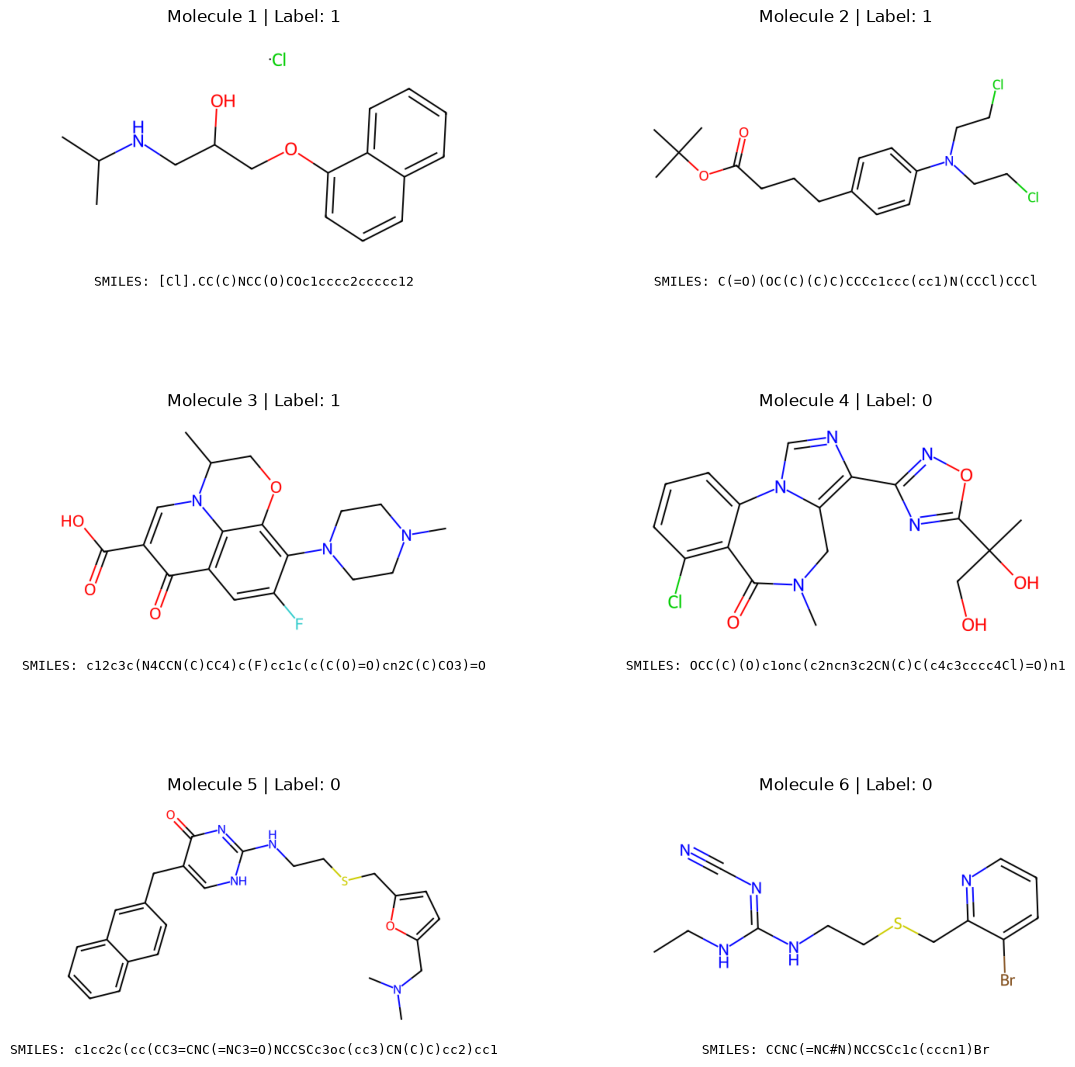

In [8]:
### Task A - Part 3 (Display at least six molecular structures, including examples from both classes. Include the SMILES string and label for every displayed molecule.)

positive_examples = [g for g in cleaned_dataset if g.y.item() == 1][:3]
negative_examples = [g for g in cleaned_dataset if g.y.item() == 0][:3]

examples = positive_examples + negative_examples

fig, axes = plt.subplots(3, 2, figsize=(14, 13))

for i, (ax, graph) in enumerate(zip(axes.flat, examples)):
    mol = Chem.MolFromSmiles(graph.smiles)

    img = Draw.MolToImage(mol, size=(550, 300))
    ax.imshow(img)
    ax.axis("off")

    label = int(graph.y.item())
    smiles = "\n".join(textwrap.wrap(graph.smiles, width=55))

    ax.set_title(f"Molecule {i + 1} | Label: {label}", fontsize=12)
    ax.text(
        0.5, -0.05,
        f"SMILES: {smiles}",
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=9,
        family="monospace"
    )

plt.subplots_adjust(hspace=0.65, wspace=0.2)
plt.show()

Atom count distribution:
  Mean: 24.22
  Median: 23.00
  Min: 2
  Max: 132
  Standard deviation: 10.67

Bond count distribution:
  Mean: 26.13
  Median: 25.00
  Min: 1
  Max: 145
  Standard deviation: 11.79


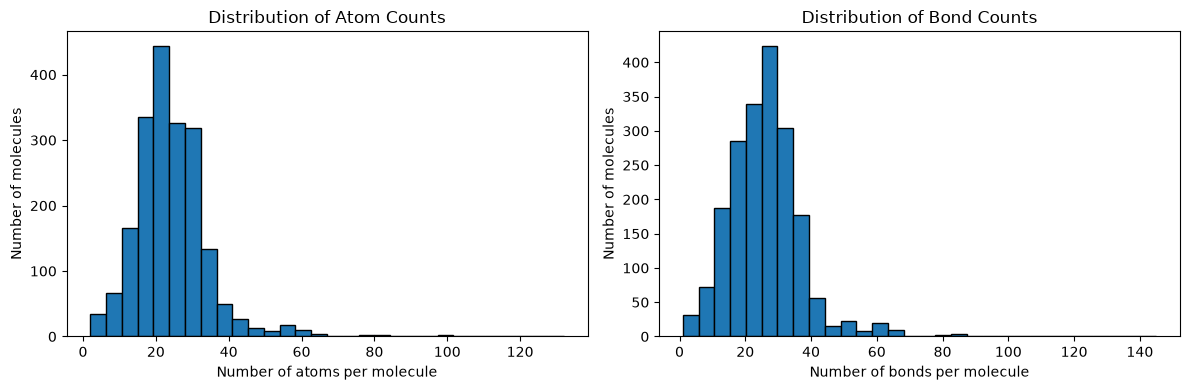

In [9]:
### Task A - Part 4 (Summarize the distributions of atom count and bond count.)

atom_counts = np.array([g.num_nodes for g in cleaned_dataset])
bond_counts = np.array([g.edge_index.size(1) // 2 for g in cleaned_dataset])

print("Atom count distribution:")
print(f"  Mean: {atom_counts.mean():.2f}")
print(f"  Median: {np.median(atom_counts):.2f}")
print(f"  Min: {atom_counts.min()}")
print(f"  Max: {atom_counts.max()}")
print(f"  Standard deviation: {atom_counts.std():.2f}")

print("\nBond count distribution:")
print(f"  Mean: {bond_counts.mean():.2f}")
print(f"  Median: {np.median(bond_counts):.2f}")
print(f"  Min: {bond_counts.min()}")
print(f"  Max: {bond_counts.max()}")
print(f"  Standard deviation: {bond_counts.std():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(atom_counts, bins=30, edgecolor="black")
axes[0].set_title("Distribution of Atom Counts")
axes[0].set_xlabel("Number of atoms per molecule")
axes[0].set_ylabel("Number of molecules")

axes[1].hist(bond_counts, bins=30, edgecolor="black")
axes[1].set_title("Distribution of Bond Counts")
axes[1].set_xlabel("Number of bonds per molecule")
axes[1].set_ylabel("Number of molecules")

plt.tight_layout()
plt.show()

### Explanation

The cleaned dataset contains an average of 24.22 atoms and 26.13 bonds per molecule. Both distributions are right-skewed. The maximum number of atoms is 132 atoms and the maximum number of bonds is 145.

In [10]:
### Task A - Part 4 (Inspect one graph and report x.shape, edge_index.shape, edge_attr.shape, y and smiles.)

graph = cleaned_dataset[0]

print("Node-feature shape:", graph.x.shape)
print("Edge-index shape:", graph.edge_index.shape)
print("Edge-feature shape:", graph.edge_attr.shape)
print("Label:", graph.y)
print("SMILES:", graph.smiles)

Node-feature shape: torch.Size([20, 9])
Edge-index shape: torch.Size([2, 40])
Edge-feature shape: torch.Size([40, 3])
Label: tensor([[1.]])
SMILES: [Cl].CC(C)NCC(O)COc1cccc2ccccc12


In [11]:
### Task B - Part 1 (Identify the meaning of each categorical atom and bond feature column.)

print("Atom features:")
for i, (name, categories) in enumerate(x_map.items()):
    print(f"Column {i}: {name} ({len(categories)} categories)")

print("\nBond features:")
for i, (name, categories) in enumerate(e_map.items()):
    print(f"Column {i}: {name} ({len(categories)} categories)")

Atom features:
Column 0: atomic_num (119 categories)
Column 1: chirality (9 categories)
Column 2: degree (11 categories)
Column 3: formal_charge (12 categories)
Column 4: num_hs (9 categories)
Column 5: num_radical_electrons (5 categories)
Column 6: hybridization (8 categories)
Column 7: is_aromatic (2 categories)
Column 8: is_in_ring (2 categories)

Bond features:
Column 0: bond_type (22 categories)
Column 1: stereo (6 categories)
Column 2: is_conjugated (2 categories)


In [12]:
### Task B - Part 1 (Encode every categorical atom and bond feature using trainable embeddings.)

class MolecularFeatureEncoder(nn.Module):
    def __init__(self, embedding_dim=32):
        super().__init__()

        self.atom_embeddings = nn.ModuleList([
            nn.Embedding(len(categories), embedding_dim)
            for categories in x_map.values()
        ])

        self.bond_embeddings = nn.ModuleList([
            nn.Embedding(len(categories), embedding_dim)
            for categories in e_map.values()
        ])

    def forward(self, x, edge_attr):
        atom_features = sum(
            embedding(x[:, i].long())
            for i, embedding in enumerate(self.atom_embeddings)
        )

        bond_features = sum(
            embedding(edge_attr[:, i].long())
            for i, embedding in enumerate(self.bond_embeddings)
        )

        return atom_features, bond_features

In [13]:
### Task B - Part 1 (Verify that categorical atom and bond features are encoded into 32-dimensional embeddings.)

encoder = MolecularFeatureEncoder(embedding_dim=32)

graph = cleaned_dataset[0]

with torch.no_grad():
    atom_features, bond_features = encoder(graph.x, graph.edge_attr)

print("Atom features before encoding:", graph.x.shape)
print("Atom features after encoding:", atom_features.shape)

print("\nBond features before encoding:", graph.edge_attr.shape)
print("Bond features after encoding:", bond_features.shape)

Atom features before encoding: torch.Size([20, 9])
Atom features after encoding: torch.Size([20, 32])

Bond features before encoding: torch.Size([40, 3])
Bond features after encoding: torch.Size([40, 32])


### Task B - Part 1 (Explain molecular graph representation, categorical features, and feature encoding.)

Each molecule is represented as a graph, where atoms are nodes and chemical bonds are edges. The `x` tensor stores atom features, `edge_index` stores the connections between atoms, and `edge_attr` stores bond features. Each bond is represented by two directed edges.

The **9 atom features** are atomic number, chirality, degree, formal charge, number of hydrogens, number of radical electrons, hybridization, aromaticity, and ring membership.

The **3 bond features** are bond type, stereochemistry, and conjugation.

I used **trainable embeddings** to encode all categorical features. Each feature has its own embedding table, with 32-dimensional vectors representing its categories. For each atom, the 9 feature embeddings are summed into one 32-dimensional vector. Similarly, the 3 bond embeddings are summed into one 32-dimensional vector per edge.

The embedding values are learned during training, so raw category codes are not treated as continuous numerical values.

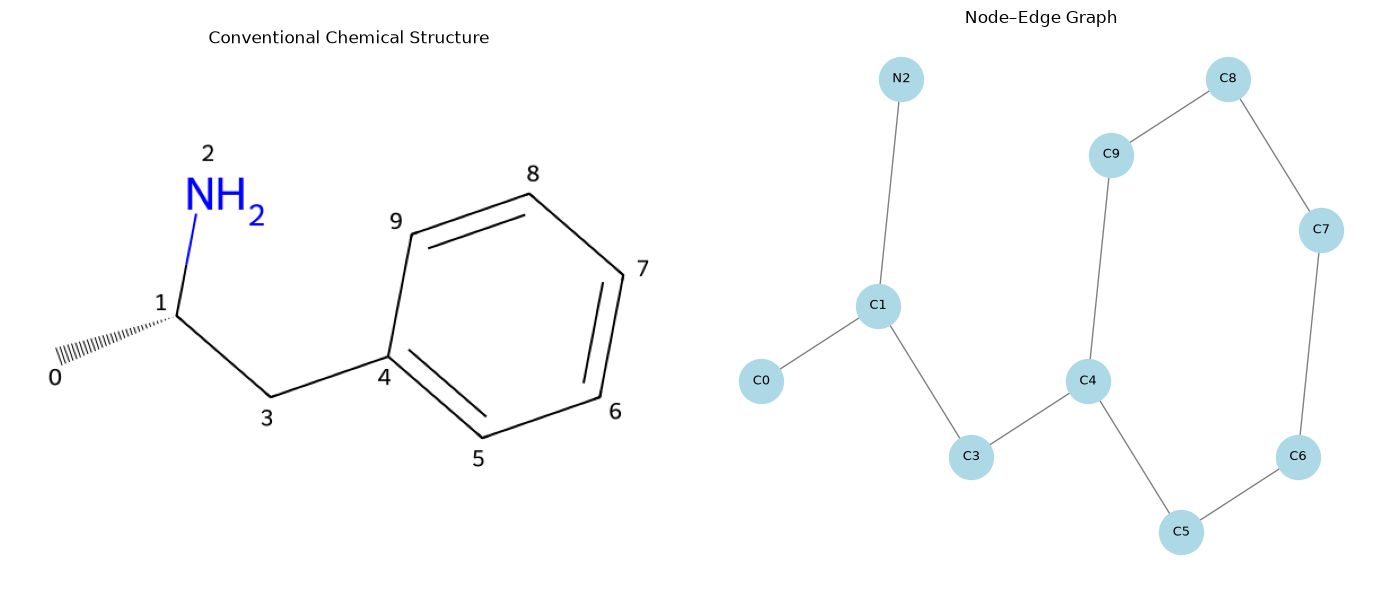

SMILES: C[C@H](N)Cc1ccccc1
Number of atoms: 10
Number of bonds: 10


In [14]:
### Task B - Part 2 (Display the same molecule as a conventional chemical structure and a node-edge graph.)

# Select a small, connected molecule for clear visualization.
graph = next(
    g for g in cleaned_dataset
    if 8 <= g.num_nodes <= 12
    and len(Chem.GetMolFrags(Chem.MolFromSmiles(g.smiles))) == 1
)

mol = Chem.MolFromSmiles(graph.smiles)
rdDepictor.Compute2DCoords(mol)

# Label atoms in the chemical structure with their indices.
for atom in mol.GetAtoms():
    atom.SetProp("atomNote", str(atom.GetIdx()))

chemical_image = Draw.MolToImage(mol, size=(600, 450))

# Build the node-edge graph using the PyG connections.
G = nx.Graph()
G.add_nodes_from(range(graph.num_nodes))
G.add_edges_from(graph.edge_index.t().tolist())

# Use the same atom positions in both representations.
conf = mol.GetConformer()
pos = {
    i: (conf.GetAtomPosition(i).x, conf.GetAtomPosition(i).y)
    for i in range(mol.GetNumAtoms())
}

node_labels = {
    atom.GetIdx(): f"{atom.GetSymbol()}{atom.GetIdx()}"
    for atom in mol.GetAtoms()
}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(chemical_image)
axes[0].set_title("Conventional Chemical Structure")
axes[0].axis("off")

nx.draw(
    G,
    pos,
    ax=axes[1],
    labels=node_labels,
    with_labels=True,
    node_size=1000,
    node_color="lightblue",
    font_size=9,
    edge_color="gray"
)

axes[1].set_title("Node–Edge Graph")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("SMILES:", graph.smiles)
print("Number of atoms:", graph.num_nodes)
print("Number of bonds:", G.number_of_edges())

### Explanation
Both views represent the same molecule, containing 10 atoms and 10 chemical bonds. Each atom in the chemical structure corresponds to a node with the same index in the node–edge graph, and each chemical bond corresponds to an edge connecting the same atoms.

The conventional chemical structure shows bond types and chemical details, while the node–edge graph shows the connections between atoms. The three bond features (bond type, stereochemistry, and conjugation) are stored in `edge_attr`.

In [15]:
### Task B - Part 3 (Create a PyTorch Geometric DataLoader. Print and explain the shapes of one batch, including x, edge_index, edge_attr, batch and y.)

loader = DataLoader(cleaned_dataset, batch_size=32, shuffle=False)

batch = next(iter(loader))

print("Number of molecules in batch:", batch.num_graphs)
print("x.shape:", batch.x.shape)
print("edge_index.shape:", batch.edge_index.shape)
print("edge_attr.shape:", batch.edge_attr.shape)
print("batch.shape:", batch.batch.shape)
print("y.shape:", batch.y.shape)

Number of molecules in batch: 32
x.shape: torch.Size([770, 9])
edge_index.shape: torch.Size([2, 1646])
edge_attr.shape: torch.Size([1646, 3])
batch.shape: torch.Size([770])
y.shape: torch.Size([32, 1])


### Task B - Part 3 (Explain the shapes of one PyTorch Geometric batch.)

The batch contains **32 molecules**, represented by the following tensors:

- **`x.shape = [770, 9]`:** Contains the features of all 770 atoms across the 32 molecules. Each atom has 9 features.
- **`edge_index.shape = [2, 1646]`:** Contains the source and destination atom indices for each of the 1,646 directed edges.
- **`edge_attr.shape = [1646, 3]`:** Contains the features of all 1,646 directed edges. Each edge has 3 bond features.
- **`batch.shape = [770]`:** For each of the 770 atoms in `x`, stores the index (0–31) of the molecule it belongs to.
- **`y.shape = [32, 1]`:** Contains one binary BBBP label for each of the 32 molecules.

In [16]:
### Task B - Part 4 (Check finite labels, non-empty graphs, matching batch labels, and no molecule loss during batching.)

# Check that every graph has a finite label and at least one atom.
assert all(torch.isfinite(g.y).all().item() for g in cleaned_dataset)
assert all(g.num_nodes > 0 for g in cleaned_dataset)

# Check every batch and count the molecules processed.
total_batched_molecules = 0

for batch in loader:
    assert batch.y.size(0) == batch.num_graphs
    assert batch.batch.numel() == batch.x.size(0)

    total_batched_molecules += batch.num_graphs

# Check that no molecules were lost during batching.
assert total_batched_molecules == len(cleaned_dataset)

print("All labels are finite: PASSED")
print("All graphs contain at least one atom: PASSED")
print("Batch labels match the number of graphs: PASSED")
print("No molecules lost during batching: PASSED")
print(f"Total molecules batched: {total_batched_molecules}")

All labels are finite: PASSED
All graphs contain at least one atom: PASSED
Batch labels match the number of graphs: PASSED
No molecules lost during batching: PASSED
Total molecules batched: 1965


In [17]:
### Task C - Part 1 (Create a 70:15:15 stratified random train-validation-test split using one fixed seed.)

SEED = 42

indices = np.arange(len(cleaned_dataset))
labels = np.array([g.y.item() for g in cleaned_dataset]).astype(int)

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    stratify=labels,
    random_state=SEED
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=labels[temp_idx],
    random_state=SEED
)

random_split = {
    "train": train_idx,
    "val": val_idx,
    "test": test_idx
}

for name, idx in random_split.items():
    print(f"{name}: {len(idx)} molecules ({len(idx) / len(indices):.2%})")

train: 1375 molecules (69.97%)
val: 295 molecules (15.01%)
test: 295 molecules (15.01%)


In [18]:
### Task C - Part 1 (Extract Bemis–Murcko scaffolds and identify invalid or acyclic molecules.)

scaffold_groups = defaultdict(list)
invalid_scaffolds = []
acyclic_molecules = []

for i, graph in enumerate(cleaned_dataset):
    mol = Chem.MolFromSmiles(graph.smiles)

    if mol is None or mol.GetNumAtoms() == 0:
        invalid_scaffolds.append(i)
        continue

    scaffold = MurckoScaffold.MurckoScaffoldSmiles(mol=mol)

    if not scaffold:
        acyclic_molecules.append(i)
        scaffold = "ACYCLIC"

    scaffold_groups[scaffold].append(i)

print("Total molecules:", len(cleaned_dataset))
print("Unique scaffold groups:", len(scaffold_groups))
print("Invalid molecules:", len(invalid_scaffolds))
print("Acyclic molecules:", len(acyclic_molecules))
print("Largest scaffold group:", max(len(v) for v in scaffold_groups.values()))

Total molecules: 1965
Unique scaffold groups: 1020
Invalid molecules: 0
Acyclic molecules: 95
Largest scaffold group: 128


[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not r

In [19]:
### Task C - Part 1 (Create a 70:15:15 Bemis-Murcko scaffold split using the same fixed seed.)

rng = np.random.default_rng(SEED)

groups = list(scaffold_groups.values())
rng.shuffle(groups)
groups.sort(key=len, reverse=True)

target_sizes = np.array([0.70, 0.15, 0.15]) * len(cleaned_dataset)
split_indices = [[], [], []]

for group in groups:
    current_sizes = np.array([len(indices) for indices in split_indices])
    remaining_capacity = target_sizes - current_sizes

    candidates = np.where(remaining_capacity >= len(group))[0]

    if len(candidates) > 0:
        chosen = candidates[np.argmax(remaining_capacity[candidates])]
    else:
        chosen = np.argmin(current_sizes + len(group) - target_sizes)

    split_indices[chosen].extend(group)

scaffold_split = {
    "train": np.array(split_indices[0]),
    "val": np.array(split_indices[1]),
    "test": np.array(split_indices[2])
}

for name, idx in scaffold_split.items():
    print(f"{name}: {len(idx)} molecules ({len(idx) / len(cleaned_dataset):.2%})")

train: 1375 molecules (69.97%)
val: 295 molecules (15.01%)
test: 295 molecules (15.01%)


### Task C - Part 1 (Document how invalid and acyclic molecules are handled.)

I used seed 42 to create separate 70:15:15 stratified random and Bemis–Murcko scaffold splits.

For the scaffold split, I grouped molecules by their Bemis–Murcko scaffolds and assigned each group entirely to one subset. No molecules were invalid after cleaning. The 95 acyclic molecules had empty scaffolds, so I assigned them to one shared scaffold group to ensure they remained in the same subset.

Both splits contain 1,375 training, 295 validation, and 295 test molecules.

In [20]:
### Task C - Part 2 (Verify complete coverage, pairwise-disjoint indices, and no canonical SMILES overlap for both splitting strategies.)

for strategy, split in [
    ("Stratified random", random_split),
    ("Bemis-Murcko scaffold", scaffold_split)
]:
    train = set(split["train"])
    val = set(split["val"])
    test = set(split["test"])

    # Complete coverage and pairwise-disjoint indices.
    assert train | val | test == set(range(len(cleaned_dataset)))
    assert train.isdisjoint(val)
    assert train.isdisjoint(test)
    assert val.isdisjoint(test)

    # No canonical SMILES overlap between subsets.
    train_smiles = {cleaned_smiles[i] for i in train}
    val_smiles = {cleaned_smiles[i] for i in val}
    test_smiles = {cleaned_smiles[i] for i in test}

    assert train_smiles.isdisjoint(val_smiles)
    assert train_smiles.isdisjoint(test_smiles)
    assert val_smiles.isdisjoint(test_smiles)

    print(f"\n{strategy} split:")
    print("Complete coverage: PASSED")
    print("Pairwise-disjoint indices: PASSED")
    print("No canonical SMILES overlap: PASSED")


Stratified random split:
Complete coverage: PASSED
Pairwise-disjoint indices: PASSED
No canonical SMILES overlap: PASSED

Bemis-Murcko scaffold split:
Complete coverage: PASSED
Pairwise-disjoint indices: PASSED
No canonical SMILES overlap: PASSED


In [21]:
### Task C - Part 3 (Report molecule counts and positive-class proportions for both splits, unique-scaffold counts for the scaffold split, and verify scaffold separation.)

scaffold_by_index = {
    i: scaffold
    for scaffold, indices in scaffold_groups.items()
    for i in indices
}

for strategy, split in [
    ("Stratified random", random_split),
    ("Bemis-Murcko scaffold", scaffold_split)
]:
    print(f"\n{strategy} split:")

    for name, indices in split.items():
        positive_count = np.sum(labels[indices] == 1)
        positive_proportion = positive_count / len(indices)

        print(
            f"{name}: {len(indices)} molecules, "
            f"positive class: {positive_count} ({positive_proportion:.2%})"
        )

        if strategy == "Bemis-Murcko scaffold":
            unique_scaffolds = {
                scaffold_by_index[i] for i in indices
            }
            print(f"  Unique scaffold groups: {len(unique_scaffolds)}")

    if strategy == "Bemis-Murcko scaffold":
        train_scaffolds = {scaffold_by_index[i] for i in split["train"]}
        val_scaffolds = {scaffold_by_index[i] for i in split["val"]}
        test_scaffolds = {scaffold_by_index[i] for i in split["test"]}

        assert train_scaffolds.isdisjoint(val_scaffolds)
        assert train_scaffolds.isdisjoint(test_scaffolds)
        assert val_scaffolds.isdisjoint(test_scaffolds)

        print("Scaffold separation: PASSED")


Stratified random split:
train: 1375 molecules, positive class: 1050 (76.36%)
val: 295 molecules, positive class: 225 (76.27%)
test: 295 molecules, positive class: 225 (76.27%)

Bemis-Murcko scaffold split:
train: 1375 molecules, positive class: 1045 (76.00%)
  Unique scaffold groups: 466
val: 295 molecules, positive class: 226 (76.61%)
  Unique scaffold groups: 277
test: 295 molecules, positive class: 229 (77.63%)
  Unique scaffold groups: 277
Scaffold separation: PASSED


### Explanation
The unique scaffold-group counts include the acyclic molecules, not just molecules with nonempty Bemis–Murcko scaffolds.

### Task C - Part 4 (Keep test sets untouched and explain why random splitting can overestimate generalization.)

I will keep both test sets untouched until final evaluation. I will use the training sets to train the models and the validation sets to select hyperparameters.

A random split can place molecules sharing the same scaffold in both training and test sets. Since the model has already learned from similar structures during training, it may perform well on the test set. This can lead to an overly optimistic estimate of generalization.

In [22]:
### Task D - Part 1 (Generate Morgan/ECFP fingerprints using RDKit.)

RADIUS = 2
FP_SIZE = 2048

fp_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=RADIUS,
    fpSize=FP_SIZE
)

fingerprints = np.array([
    fp_generator.GetFingerprintAsNumPy(Chem.MolFromSmiles(g.smiles))
    for g in cleaned_dataset
])

print("Radius:", RADIUS)
print("Fingerprint length:", FP_SIZE)
print("Fingerprint matrix shape:", fingerprints.shape)

[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not r

Radius: 2
Fingerprint length: 2048
Fingerprint matrix shape: (1965, 2048)


[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not removing hydrogen atom without neighbors
[10:56:06] WARNING: not r

### Task D - Part 1 (State the fingerprint radius, length, and what it represents.)

I used Morgan fingerprints (ECFP4) with a radius of 2 and a length of 2,048 bits. Each fingerprint is a binary vector representing the molecular substructures around atoms, considering neighbors up to two bonds away.

In [23]:
### Task D - Part 2 (Train class-balanced logistic regression models and select C using validation ROC-AUC.)

C_VALUES = [0.01, 0.1, 1, 10, 100]

best_baseline_models = {}
best_baseline_params = {}

for strategy, split in [
    ("Stratified random", random_split),
    ("Bemis-Murcko scaffold", scaffold_split)
]:
    train_idx = split["train"]
    val_idx = split["val"]

    best_auc = -1

    print(f"\n{strategy} split:")

    for C in C_VALUES:
        model = LogisticRegression(
            C=C,
            class_weight="balanced",
            max_iter=2000,
            random_state=SEED
        )

        model.fit(fingerprints[train_idx], labels[train_idx])

        val_probs = model.predict_proba(fingerprints[val_idx])[:, 1]
        val_auc = roc_auc_score(labels[val_idx], val_probs)

        print(f"C={C}: Validation ROC-AUC = {val_auc:.4f}")

        if val_auc > best_auc:
            best_auc = val_auc
            best_baseline_models[strategy] = model
            best_baseline_params[strategy] = C

    print()
    print(f"Best C: {best_baseline_params[strategy]}")
    print(f"Best validation ROC-AUC: {best_auc:.4f}")


Stratified random split:
C=0.01: Validation ROC-AUC = 0.8992
C=0.1: Validation ROC-AUC = 0.9024
C=1: Validation ROC-AUC = 0.8968
C=10: Validation ROC-AUC = 0.8865
C=100: Validation ROC-AUC = 0.8863

Best C: 0.1
Best validation ROC-AUC: 0.9024

Bemis-Murcko scaffold split:
C=0.01: Validation ROC-AUC = 0.8758
C=0.1: Validation ROC-AUC = 0.8886
C=1: Validation ROC-AUC = 0.8773
C=10: Validation ROC-AUC = 0.8616
C=100: Validation ROC-AUC = 0.8584

Best C: 0.1
Best validation ROC-AUC: 0.8886


### Task D - Part 2 (Explain logistic regression training, class weighting, and model selection.)

I trained 10 candidate logistic regression models, 5 for each splitting strategy, using different values of `C`. Each model was trained using only its corresponding training subset.

I used balanced class weights because the dataset contains more positive than negative molecules. The weights were calculated from each training subset only, giving greater importance to the minority class (non-BBB-penetrating molecules).

I selected the best model for each splitting strategy based on validation ROC-AUC, resulting in two selected baseline models.

In [24]:
### Task D - Part 3 (Select one decision threshold per model using validation data.)

THRESHOLDS = np.arange(0.10, 0.91, 0.05)

best_baseline_thresholds = {}

for strategy, split in [
    ("Stratified random", random_split),
    ("Bemis-Murcko scaffold", scaffold_split)
]:
    model = best_baseline_models[strategy]
    val_idx = split["val"]

    val_probs = model.predict_proba(fingerprints[val_idx])[:, 1]

    scores = [
        f1_score(
            labels[val_idx],
            (val_probs >= threshold).astype(int),
            average="macro"
        )
        for threshold in THRESHOLDS
    ]

    best_index = np.argmax(scores)
    best_threshold = THRESHOLDS[best_index]

    best_baseline_thresholds[strategy] = float(best_threshold)

    print(f"\n{strategy} split:")
    print(f"Selected C: {best_baseline_params[strategy]}")
    print(f"Selected threshold: {best_threshold:.2f}")
    print(f"Validation macro-F1: {scores[best_index]:.4f}")


Stratified random split:
Selected C: 0.1
Selected threshold: 0.30
Validation macro-F1: 0.8553

Bemis-Murcko scaffold split:
Selected C: 0.1
Selected threshold: 0.40
Validation macro-F1: 0.7903


### Task D - Part 4 (Report the random seed and settings needed to reproduce the baseline.)

I used the following settings for both splitting strategies:

| Setting | Value |
|---|---|
| Random seed | 42 |
| Dataset | BBBP (1,965 cleaned molecules) |
| Split strategies | Stratified random and Bemis–Murcko scaffold |
| Train/validation/test ratio | 70:15:15 |
| Fingerprint | Morgan (ECFP4) |
| Fingerprint radius | 2 |
| Fingerprint length | 2,048 bits |
| Classifier | Logistic regression |
| Class weighting | Balanced, calculated from training labels |
| Hyperparameter candidates (C) | 0.01, 0.1, 1, 10, 100 |
| Selected C (both splits) | 0.1 |
| Maximum iterations | 2,000 |
| Hyperparameter selection | Validation ROC-AUC |
| Threshold candidates | 0.10 to 0.90, in steps of 0.05 |
| Selected threshold (random split) | 0.30 |
| Selected threshold (scaffold split) | 0.40 |
| Threshold selection | Validation macro-F1 |

All models were fitted using their respective training subsets. Validation data was used for model selection, and the test sets were reserved for final evaluation.

In [25]:
### Task E - Part 1 (Implement a bond-aware GNN with two message-passing layers, graph-level pooling, and a binary-classification head.)

class MolecularGNN(nn.Module):
    def __init__(self, hidden_dim=32):
        super().__init__()

        self.encoder = MolecularFeatureEncoder(embedding_dim=hidden_dim)

        self.conv1 = GINEConv(
            nn.Sequential(
                nn.Linear(hidden_dim, hidden_dim),
                nn.ReLU(),
                nn.Linear(hidden_dim, hidden_dim)
            )
        )

        self.conv2 = GINEConv(
            nn.Sequential(
                nn.Linear(hidden_dim, hidden_dim),
                nn.ReLU(),
                nn.Linear(hidden_dim, hidden_dim)
            )
        )

        self.classifier = nn.Linear(hidden_dim, 1)

    def forward(self, data):
        x, edge_attr = self.encoder(data.x, data.edge_attr)

        x = F.relu(self.conv1(x, data.edge_index, edge_attr))
        x = F.relu(self.conv2(x, data.edge_index, edge_attr))

        x = global_mean_pool(x, data.batch)

        return self.classifier(x).squeeze(-1)

In [26]:
### Task E - Part 1 (Verify the GNN output shape and report its trainable parameter count.)

model = MolecularGNN(hidden_dim=32)
model.eval()

batch = next(iter(loader))

with torch.no_grad():
    logits = model(batch)

print("Number of molecules in batch:", batch.num_graphs)
print("Model output shape:", logits.shape)
print("Total trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))

Number of molecules in batch: 32
Model output shape: torch.Size([32])
Total trainable parameters: 10881


### Task E - Part 1 (Report the GNN architecture, feature encoding, and parameter count.)

I implemented a bond-aware GNN with two GINEConv message-passing layers, each taking 32-dimensional atom representations as input and producing updated 32-dimensional atom representations.

**Feature encoding:** I used 32-dimensional trainable embeddings for all 9 categorical atom features and 3 categorical bond features. For each atom, the embeddings of its 9 features are added together to produce one 32-dimensional atom embedding. Similarly, the embeddings of the 3 bond features are added to produce one 32-dimensional bond embedding.

**Message passing:** Each GINEConv layer receives the atom embeddings, bond embeddings, and `edge_index`, which identifies the connections between atoms. To update an atom, the layer adds each neighboring atom's embedding to the embedding of their connecting bond and applies ReLU. It then sums these messages from all neighbors, adds the result to the atom's own embedding, and passes the combined vector through an MLP to produce an updated 32-dimensional atom embedding. The second GINEConv layer repeats this process using the updated atom embeddings.

**Global mean pooling:** After message passing, the updated embeddings of all atoms belonging to the same molecule are averaged to produce one 32-dimensional embedding per molecule.

**Classification:** A linear layer converts each molecule's embedding into one logit for BBB penetration prediction.

The model has **10,881 trainable parameters**.

### Task E - Part 2 (State and justify the GNN training configuration and model selection.)

I used `BCEWithLogitsLoss` because BBB penetration prediction is a binary-classification task. I chose the Adam optimizer with a learning rate of 0.001 and a batch size of 32 for efficient training.

I set a maximum of 100 training epochs and used **early stopping** to terminate training if the validation ROC-AUC does not improve for 15 consecutive epochs. The model checkpoint with the highest validation ROC-AUC is retained.

To handle class imbalance, I used **class-weighted loss**, with weights calculated from each training subset to give more importance to the minority class (non-BBB-penetrating molecules) during training.

Model selection uses validation data only, while the test sets remain untouched until final evaluation.

In [27]:
### Task E - Part 3 (Create training and validation DataLoaders for both splitting strategies.)

gnn_loaders = {}

for strategy, split in [
    ("Stratified random", random_split),
    ("Bemis-Murcko scaffold", scaffold_split)
]:
    train_data = [cleaned_dataset[i] for i in split["train"]]
    val_data = [cleaned_dataset[i] for i in split["val"]]

    gnn_loaders[strategy] = {
        "train": DataLoader(train_data, batch_size=32, shuffle=True),
        "val": DataLoader(val_data, batch_size=32, shuffle=False)
    }

    print(f"{strategy}:")
    print(f"  Training molecules: {len(train_data)}")
    print(f"  Validation molecules: {len(val_data)}")

Stratified random:
  Training molecules: 1375
  Validation molecules: 295
Bemis-Murcko scaffold:
  Training molecules: 1375
  Validation molecules: 295


In [28]:
### Task E - Part 3 (Implement GNN training and validation functions to track loss and validation ROC-AUC.)

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    total_molecules = 0

    for batch in loader:
        optimizer.zero_grad()

        logits = model(batch)
        targets = batch.y.view(-1).float()

        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * batch.num_graphs
        total_molecules += batch.num_graphs

    return total_loss / total_molecules


@torch.no_grad()
def validate(model, loader, criterion):
    model.eval()

    total_loss = 0
    total_molecules = 0
    all_probs = []
    all_labels = []

    for batch in loader:
        logits = model(batch)
        targets = batch.y.view(-1).float()

        loss = criterion(logits, targets)

        total_loss += loss.item() * batch.num_graphs
        total_molecules += batch.num_graphs

        all_probs.extend(torch.sigmoid(logits).cpu().numpy())
        all_labels.extend(targets.cpu().numpy())

    val_loss = total_loss / total_molecules
    val_auc = roc_auc_score(all_labels, all_probs)

    return val_loss, val_auc

In [29]:
### Task E - Part 3 (Implement GNN training with class-weighted loss, early stopping, and checkpoint selection.)

def train_gnn(model, train_loader, val_loader, max_epochs=100, patience=15):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    train_labels = torch.cat([
        batch.y.view(-1) for batch in train_loader
    ])

    n_positive = (train_labels == 1).sum().item()
    n_negative = (train_labels == 0).sum().item()

    pos_weight = torch.tensor([n_negative / n_positive])
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_auc": []
    }

    best_auc = -float("inf")
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0

    for epoch in range(1, max_epochs + 1):
        train_loss = train_one_epoch(
            model, train_loader, optimizer, criterion
        )
        val_loss, val_auc = validate(model, val_loader, criterion)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_auc"].append(val_auc)

        if val_auc > best_auc:
            best_auc = val_auc
            best_epoch = epoch
            best_state = {
                name: tensor.detach().clone()
                for name, tensor in model.state_dict().items()
            }
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    model.load_state_dict(best_state)

    return model, history, best_epoch, best_auc

In [30]:
### Task E - Part 3 (Train the GNN on both splitting strategies and record validation performance.)

gnn_results = {}

for strategy, loaders in gnn_loaders.items():
    torch.manual_seed(SEED)
    model = MolecularGNN(hidden_dim=32)

    trained_model, history, best_epoch, best_auc = train_gnn(
        model,
        loaders["train"],
        loaders["val"]
    )

    gnn_results[strategy] = {
        "model": trained_model,
        "history": history,
        "best_epoch": best_epoch,
        "best_val_auc": best_auc
    }

    print(f"\n{strategy}:")
    print(f"  Epochs trained: {len(history['train_loss'])}")
    print(f"  Best epoch: {best_epoch}")
    print(f"  Best validation ROC-AUC: {best_auc:.4f}")

    print("\nEpoch | Train Loss | Val Loss | Val ROC-AUC")
    print("-" * 47)

    for epoch, (train_loss, val_loss, val_auc) in enumerate(
        zip(
            history["train_loss"],
            history["val_loss"],
            history["val_auc"]
        ),
        start=1
    ):
        marker = " <-- Best ROC-AUC" if epoch == best_epoch else ""

        print(
            f"{epoch:5d} | "
            f"{train_loss:10.4f} | "
            f"{val_loss:8.4f} | "
            f"{val_auc:11.4f}{marker}"
        )


Stratified random:
  Epochs trained: 32
  Best epoch: 17
  Best validation ROC-AUC: 0.8816

Epoch | Train Loss | Val Loss | Val ROC-AUC
-----------------------------------------------
    1 |     0.3213 |   0.3050 |      0.7389
    2 |     0.2936 |   0.2786 |      0.7765
    3 |     0.2704 |   0.3003 |      0.8051
    4 |     0.2709 |   0.2636 |      0.8083
    5 |     0.2611 |   0.2741 |      0.8300
    6 |     0.2615 |   0.2524 |      0.8310
    7 |     0.2541 |   0.2435 |      0.8369
    8 |     0.2502 |   0.2517 |      0.8374
    9 |     0.2428 |   0.2389 |      0.8531
   10 |     0.2460 |   0.2307 |      0.8651
   11 |     0.2359 |   0.2305 |      0.8628
   12 |     0.2341 |   0.2258 |      0.8662
   13 |     0.2287 |   0.2422 |      0.8748
   14 |     0.2298 |   0.2185 |      0.8740
   15 |     0.2289 |   0.2181 |      0.8800
   16 |     0.2249 |   0.2257 |      0.8775
   17 |     0.2237 |   0.2193 |      0.8816 <-- Best ROC-AUC
   18 |     0.2228 |   0.2184 |      0.8789
   19 

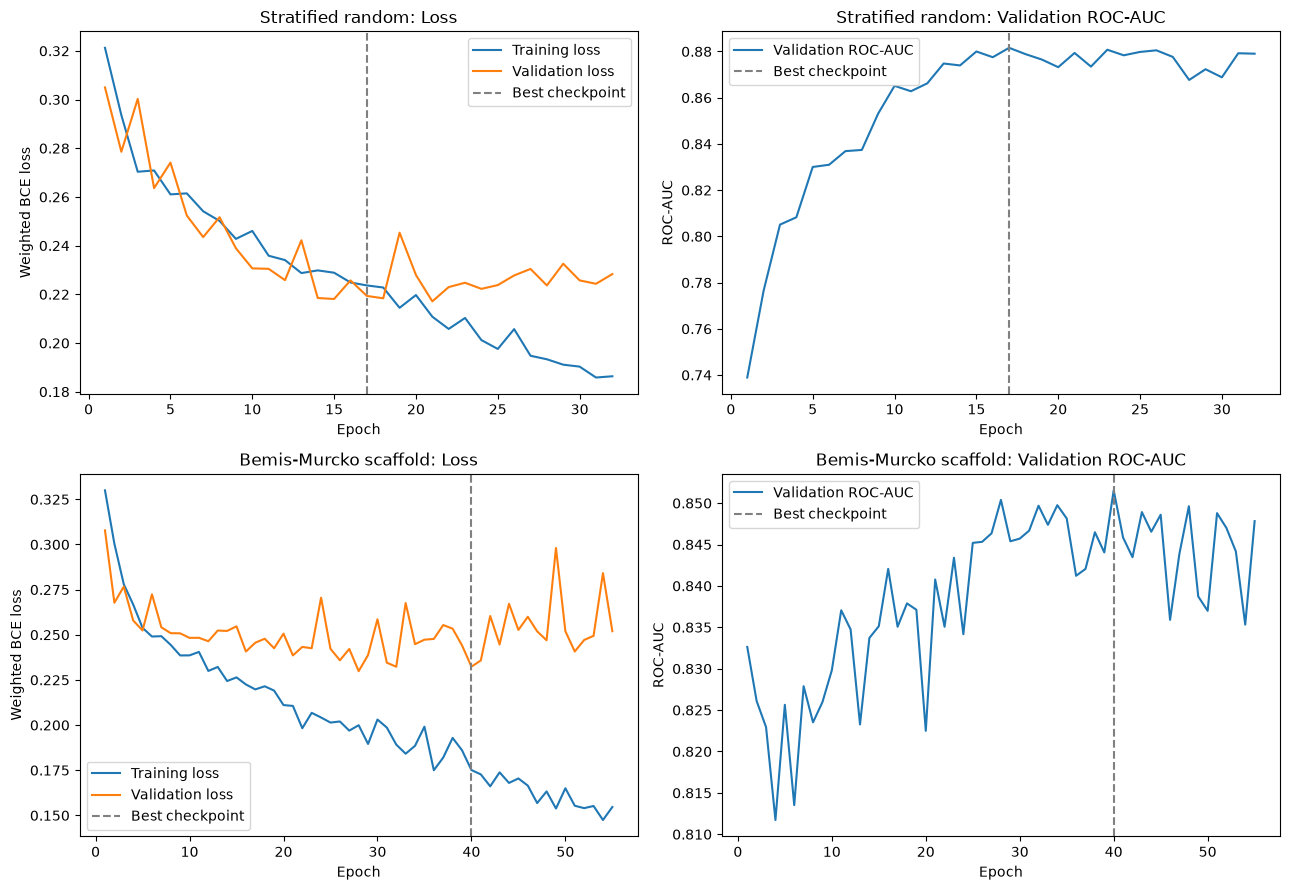

In [31]:
### Task E - Part 3 (Plot training loss, validation loss, and validation ROC-AUC for both splitting strategies.)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for row, (strategy, result) in enumerate(gnn_results.items()):
    history = result["history"]
    epochs = range(1, len(history["train_loss"]) + 1)

    axes[row, 0].plot(epochs, history["train_loss"], label="Training loss")
    axes[row, 0].plot(epochs, history["val_loss"], label="Validation loss")
    axes[row, 0].axvline(
        result["best_epoch"], linestyle="--", color="gray",
        label="Best checkpoint"
    )
    axes[row, 0].set_title(f"{strategy}: Loss")
    axes[row, 0].set_xlabel("Epoch")
    axes[row, 0].set_ylabel("Weighted BCE loss")
    axes[row, 0].legend()

    axes[row, 1].plot(epochs, history["val_auc"], label="Validation ROC-AUC")
    axes[row, 1].axvline(
        result["best_epoch"], linestyle="--", color="gray",
        label="Best checkpoint"
    )
    axes[row, 1].set_title(f"{strategy}: Validation ROC-AUC")
    axes[row, 1].set_xlabel("Epoch")
    axes[row, 1].set_ylabel("ROC-AUC")
    axes[row, 1].legend()

plt.tight_layout()
plt.show()

### Task E - Part 3 (Interpret training and validation curves.)

**Stratified random split:**

- **Underfitting:** No clear evidence of underfitting. Training loss decreases, and validation ROC-AUC improves substantially, reaching 0.8816 at epoch 17.
- **Instability:** Validation loss fluctuates throughout training, while validation ROC-AUC remains relatively stable with small fluctuations after epoch 17.
- **Overfitting:** After epoch 17, training loss continues decreasing, but validation ROC-AUC does not improve beyond its previous maximum, and validation loss shows no sustained improvement. This suggests mild overfitting.

**Bemis–Murcko scaffold split:**

- **Underfitting:** No clear evidence of underfitting. Training loss decreases, and validation ROC-AUC reaches 0.8515 at epoch 40.
- **Instability:** Validation loss fluctuates throughout training, while validation ROC-AUC shows more irregular ups and downs than in the stratified random split, despite an overall upward trend.
- **Overfitting:** After epoch 40, training loss generally continues decreasing, but validation ROC-AUC does not improve beyond its previous maximum, and validation loss shows no sustained improvement. This suggests overfitting.

For both splits, early stopping retains the checkpoint with the highest validation ROC-AUC. These conclusions are based only on training and validation results, without using the test sets.

In [32]:
### Task E - Part 4 (Train the GNN with three random seeds, retain checkpoints, and select validation-based thresholds.)

GNN_SEEDS = [42, 43, 44]

gnn_seed_results = {}

for strategy, loaders in gnn_loaders.items():
    gnn_seed_results[strategy] = []

    print(f"\n{strategy}:")

    for seed in GNN_SEEDS:
        if seed == SEED:
            result = gnn_results[strategy]
            trained_model = result["model"]
            best_epoch = result["best_epoch"]
            best_auc = result["best_val_auc"]
        else:
            torch.manual_seed(seed)
            model = MolecularGNN(hidden_dim=32)

            trained_model, history, best_epoch, best_auc = train_gnn(
                model,
                loaders["train"],
                loaders["val"]
            )

        trained_model.eval()
        val_probs = []
        val_labels = []

        with torch.no_grad():
            for batch in loaders["val"]:
                logits = trained_model(batch)

                val_probs.extend(torch.sigmoid(logits).cpu().numpy())
                val_labels.extend(batch.y.view(-1).cpu().numpy())

        val_probs = np.array(val_probs)
        val_labels = np.array(val_labels).astype(int)

        best_threshold = None
        best_f1 = -1

        for threshold in THRESHOLDS:
            predictions = (val_probs >= threshold).astype(int)
            score = f1_score(val_labels, predictions, average="macro")

            if score > best_f1:
                best_f1 = score
                best_threshold = float(threshold)

        gnn_seed_results[strategy].append({
            "seed": seed,
            "best_epoch": best_epoch,
            "best_val_auc": best_auc,
            "model": trained_model,
            "threshold": best_threshold,
            "val_macro_f1": best_f1
        })

        print(
            f"  Seed {seed}: "
            f"Best epoch = {best_epoch}, "
            f"Validation ROC-AUC = {best_auc:.4f}, "
            f"Threshold = {best_threshold:.2f}, "
            f"Validation macro-F1 = {best_f1:.4f}"
        )


Stratified random:
  Seed 42: Best epoch = 17, Validation ROC-AUC = 0.8816, Threshold = 0.50, Validation macro-F1 = 0.8126
  Seed 43: Best epoch = 84, Validation ROC-AUC = 0.8894, Threshold = 0.50, Validation macro-F1 = 0.8592
  Seed 44: Best epoch = 81, Validation ROC-AUC = 0.9131, Threshold = 0.30, Validation macro-F1 = 0.8567

Bemis-Murcko scaffold:
  Seed 42: Best epoch = 40, Validation ROC-AUC = 0.8515, Threshold = 0.50, Validation macro-F1 = 0.7769
  Seed 43: Best epoch = 26, Validation ROC-AUC = 0.8590, Threshold = 0.40, Validation macro-F1 = 0.7774
  Seed 44: Best epoch = 98, Validation ROC-AUC = 0.8544, Threshold = 0.20, Validation macro-F1 = 0.7768


In [33]:
### Task E - Part 4 (Calculate mean and standard deviation of validation ROC-AUC across three seeds.)

gnn_seed_summary = {}

for strategy, runs in gnn_seed_results.items():
    aucs = np.array([run["best_val_auc"] for run in runs])

    mean_auc = aucs.mean()
    std_auc = aucs.std(ddof=1)

    gnn_seed_summary[strategy] = {
        "mean": mean_auc,
        "std": std_auc
    }

    print(f"{strategy}:")
    print(f"  Mean validation ROC-AUC: {mean_auc:.4f}")
    print(f"  Standard deviation: {std_auc:.4f}")
    print(f"  Mean ± SD: {mean_auc:.4f} ± {std_auc:.4f}")

Stratified random:
  Mean validation ROC-AUC: 0.8947
  Standard deviation: 0.0164
  Mean ± SD: 0.8947 ± 0.0164
Bemis-Murcko scaffold:
  Mean validation ROC-AUC: 0.8550
  Standard deviation: 0.0038
  Mean ± SD: 0.8550 ± 0.0038


### Task E - Part 4 (Report GNN performance across three random seeds.)

I trained the GNN with three random seeds (42, 43, and 44) for each splitting strategy, keeping the dataset splits and training settings unchanged.

- **Stratified random split:** Mean validation ROC-AUC = 0.8947 ± 0.0164 (standard deviation).
- **Bemis–Murcko scaffold split:** Mean validation ROC-AUC = 0.8550 ± 0.0038 (standard deviation).

**Seed variation:** The standard deviation shows how much performance varies across different training seeds within the same split. The random split has higher variation (0.0164) than the scaffold split (0.0038).

**Effect of splitting strategy:** The random split achieves a mean validation ROC-AUC that is 0.0397 higher than the scaffold split. This suggests that the splitting strategy influences the measured performance. However, the difference cannot be attributed to the splitting method alone.

All results are based on validation data, without using the test sets.

In [34]:
### Task F - Part 1 (Retrieve the best GNN checkpoints and validation-selected thresholds.)

best_gnn_seeds = {}
best_gnn_models = {}
best_gnn_thresholds = {}

for strategy, runs in gnn_seed_results.items():
    best_run = max(runs, key=lambda run: run["best_val_auc"])

    best_gnn_seeds[strategy] = best_run["seed"]
    best_gnn_models[strategy] = best_run["model"]
    best_gnn_thresholds[strategy] = best_run["threshold"]

    print(f"{strategy}:")
    print(f"  Selected seed: {best_run['seed']}")
    print(f"  Best epoch: {best_run['best_epoch']}")
    print(f"  Validation ROC-AUC: {best_run['best_val_auc']:.4f}")
    print(f"  Selected threshold: {best_run['threshold']:.2f}")
    print(f"  Validation macro-F1: {best_run['val_macro_f1']:.4f}")

Stratified random:
  Selected seed: 44
  Best epoch: 81
  Validation ROC-AUC: 0.9131
  Selected threshold: 0.30
  Validation macro-F1: 0.8567
Bemis-Murcko scaffold:
  Selected seed: 43
  Best epoch: 26
  Validation ROC-AUC: 0.8590
  Selected threshold: 0.40
  Validation macro-F1: 0.7774


In [35]:
### Task F - Part 1 (Prepare test DataLoaders for both splitting strategies.)

gnn_test_loaders = {}

for strategy, split in [
    ("Stratified random", random_split),
    ("Bemis-Murcko scaffold", scaffold_split)
]:
    test_data = [cleaned_dataset[i] for i in split["test"]]

    gnn_test_loaders[strategy] = DataLoader(
        test_data,
        batch_size=32,
        shuffle=False
    )

    print(f"{strategy}:")
    print(f"  Test molecules: {len(test_data)}")

Stratified random:
  Test molecules: 295
Bemis-Murcko scaffold:
  Test molecules: 295


In [36]:
### Task F - Part 1 (Calculate the six required evaluation metrics using validation-selected thresholds.)

def evaluate_predictions(y_true, y_probs, threshold):
    y_true = np.asarray(y_true).astype(int)
    y_probs = np.asarray(y_probs)

    y_pred = (y_probs >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "ROC-AUC": roc_auc_score(y_true, y_probs),
        "PR-AUC": average_precision_score(y_true, y_probs),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "F1": f1_score(y_true, y_pred),
    }

In [37]:
### Task F - Part 1 (Evaluate both models under both splitting strategies and display one comparison table.)

test_results = {}
comparison_rows = []

for strategy, split in [
    ("Stratified random", random_split),
    ("Bemis-Murcko scaffold", scaffold_split)
]:
    test_indices = split["test"]
    y_test = labels[test_indices]

    # Fingerprint baseline
    baseline_probs = best_baseline_models[strategy].predict_proba(
        fingerprints[test_indices]
    )[:, 1]

    baseline_metrics = evaluate_predictions(
        y_test,
        baseline_probs,
        best_baseline_thresholds[strategy]
    )

    # GNN
    model = best_gnn_models[strategy]
    model.eval()

    gnn_probs = []
    gnn_labels = []

    with torch.no_grad():
        for batch in gnn_test_loaders[strategy]:
            logits = model(batch)

            gnn_probs.extend(torch.sigmoid(logits).cpu().numpy())
            gnn_labels.extend(batch.y.view(-1).cpu().numpy())

    assert np.array_equal(y_test, np.array(gnn_labels).astype(int))

    gnn_metrics = evaluate_predictions(
        gnn_labels,
        gnn_probs,
        best_gnn_thresholds[strategy]
    )

    test_results[strategy] = {
        "Fingerprint baseline": baseline_metrics,
        "GNN": gnn_metrics
    }

    # Add both models to the comparison table
    for model_name, metrics in test_results[strategy].items():
        threshold = (
            best_baseline_thresholds[strategy]
            if model_name == "Fingerprint baseline"
            else best_gnn_thresholds[strategy]
        )

        comparison_rows.append({
            "Model": model_name,
            "Split": strategy,
            "Threshold": threshold,
            **metrics
        })

results_df = pd.DataFrame(comparison_rows)

display(
    results_df.style.format({
        "Threshold": "{:.2f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}",
        "Accuracy": "{:.4f}",
        "Sensitivity": "{:.4f}",
        "Specificity": "{:.4f}",
        "F1": "{:.4f}"
    }).hide(axis="index")
)

Model,Split,Threshold,ROC-AUC,PR-AUC,Accuracy,Sensitivity,Specificity,F1
Fingerprint baseline,Stratified random,0.30,0.8917,0.9550,0.8746,0.9689,0.5714,0.9218
GNN,Stratified random,0.30,0.9088,0.9673,0.8780,0.9467,0.6571,0.9221
Fingerprint baseline,Bemis-Murcko scaffold,0.40,0.9134,0.9720,0.8847,0.9607,0.6212,0.9283
GNN,Bemis-Murcko scaffold,0.40,0.8630,0.9519,0.8508,0.9301,0.5758,0.9064


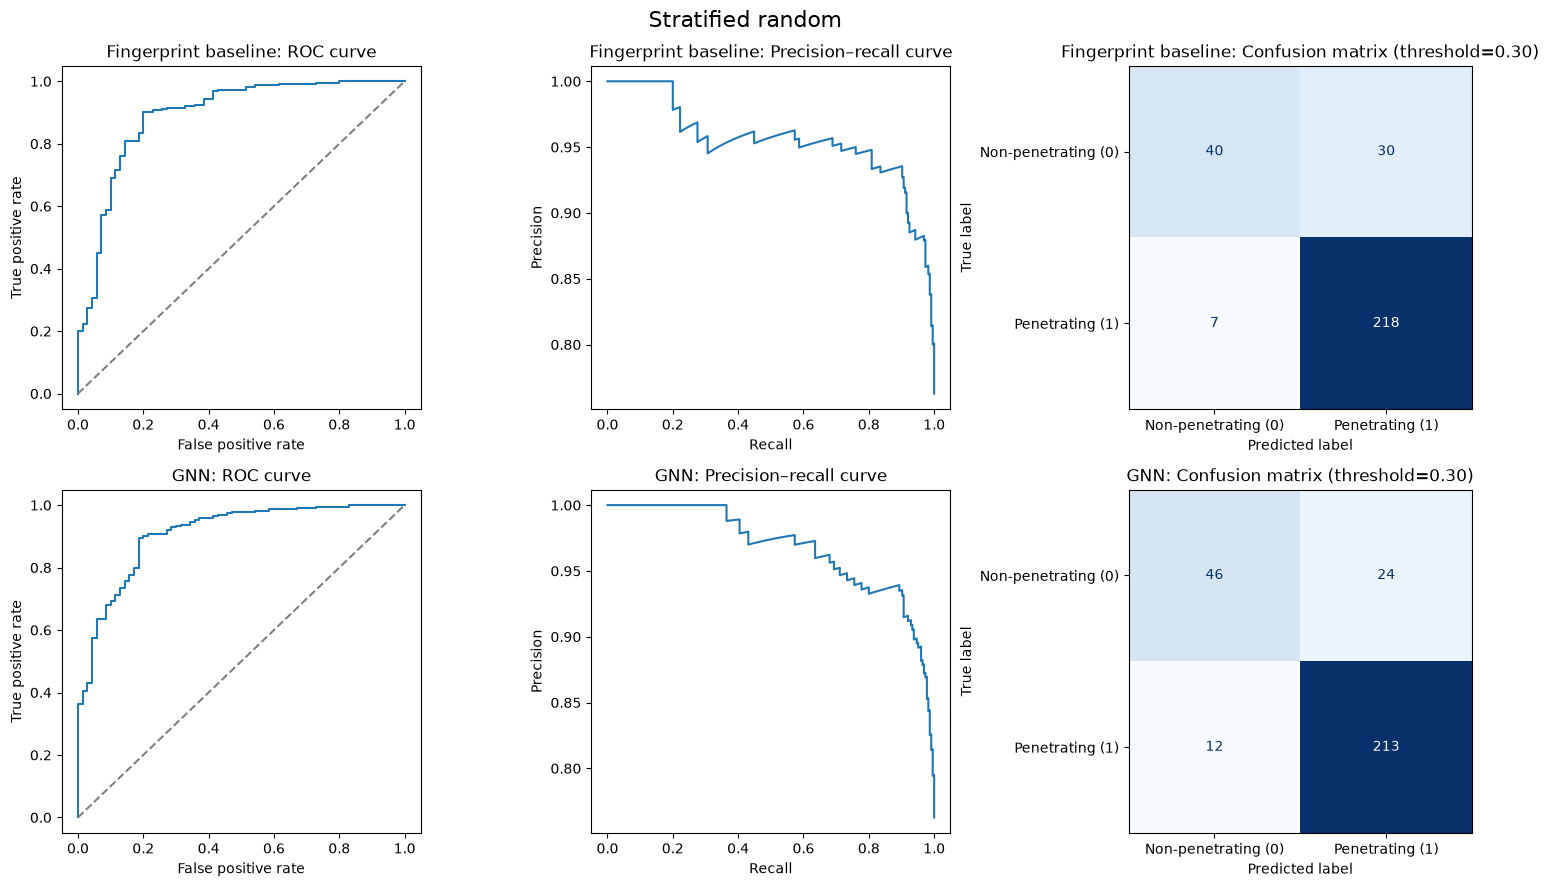

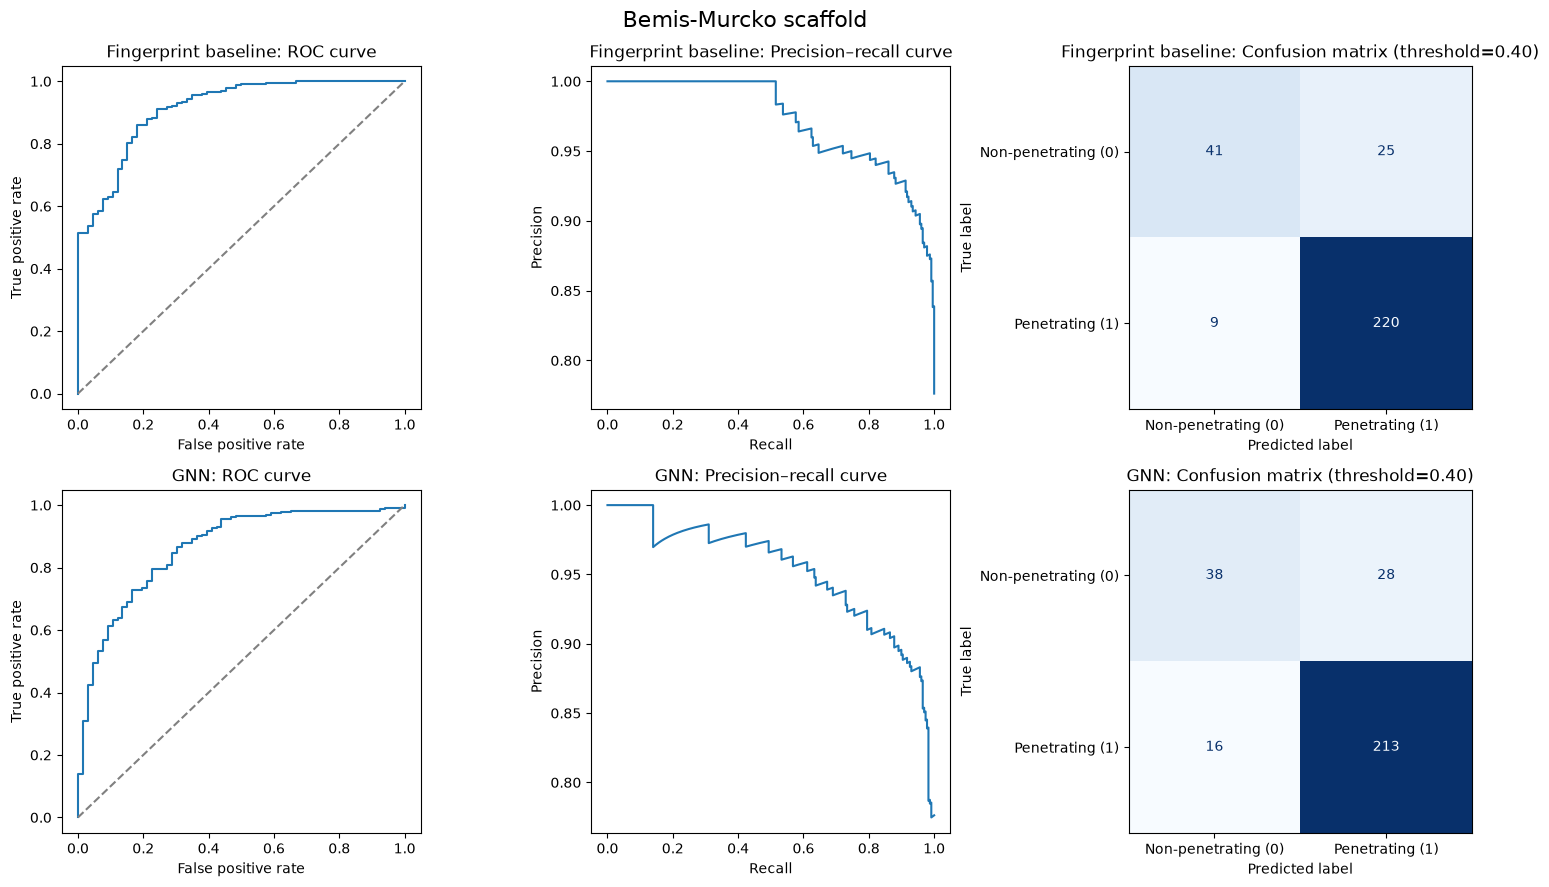

In [38]:
### Task F - Part 2 (Plot ROC curves, precision–recall curves, and confusion matrices for both models under both splitting strategies.)

for strategy, split in [
    ("Stratified random", random_split),
    ("Bemis-Murcko scaffold", scaffold_split)
]:
    test_indices = split["test"]
    y_test = labels[test_indices]

    baseline_probs = best_baseline_models[strategy].predict_proba(
        fingerprints[test_indices]
    )[:, 1]

    model = best_gnn_models[strategy]
    model.eval()

    gnn_probs = []
    with torch.no_grad():
        for batch in gnn_test_loaders[strategy]:
            gnn_probs.extend(
                torch.sigmoid(model(batch)).cpu().numpy()
            )

    evaluations = [
        ("Fingerprint baseline", baseline_probs, best_baseline_thresholds[strategy]),
        ("GNN", np.array(gnn_probs), best_gnn_thresholds[strategy])
    ]

    fig, axes = plt.subplots(2, 3, figsize=(15, 9))

    for row, (model_name, probs, threshold) in enumerate(evaluations):
        fpr, tpr, _ = roc_curve(y_test, probs)
        precision, recall, _ = precision_recall_curve(y_test, probs)
        predictions = (np.asarray(probs) >= threshold).astype(int)

        axes[row, 0].plot(fpr, tpr)
        axes[row, 0].plot([0, 1], [0, 1], "--", color="gray")
        axes[row, 0].set_title(f"{model_name}: ROC curve")
        axes[row, 0].set_xlabel("False positive rate")
        axes[row, 0].set_ylabel("True positive rate")

        axes[row, 1].plot(recall, precision)
        axes[row, 1].set_title(f"{model_name}: Precision–recall curve")
        axes[row, 1].set_xlabel("Recall")
        axes[row, 1].set_ylabel("Precision")

        cm = confusion_matrix(y_test, predictions, labels=[0, 1])

        ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["Non-penetrating (0)", "Penetrating (1)"]
        ).plot(ax=axes[row, 2], cmap="Blues", colorbar=False)

        axes[row, 2].set_title(
            f"{model_name}: Confusion matrix (threshold={threshold:.2f})"
        )

    fig.suptitle(strategy, fontsize=16)
    plt.tight_layout()
    plt.show()

In [39]:
### Task F - Part 3 (Compare both models across splitting strategies, including individual GNN seeds and mean ± SD.)

metric_names = [
    "ROC-AUC", "PR-AUC", "Accuracy",
    "Sensitivity", "Specificity", "F1"
]

gnn_test_seed_results = {}
comparison_rows = []

for strategy, runs in gnn_seed_results.items():
    gnn_test_seed_results[strategy] = []

    # Fingerprint baseline
    baseline_metrics = test_results[strategy]["Fingerprint baseline"]

    comparison_rows.append({
        "Split": strategy,
        "Model": "Fingerprint baseline",
        "Seed": "—",
        "Threshold": f"{best_baseline_thresholds[strategy]:.2f}",
        **{
            metric: f"{baseline_metrics[metric]:.4f}"
            for metric in metric_names
        }
    })

    # Evaluate each saved GNN seed
    for run in runs:
        model = run["model"]
        threshold = run["threshold"]
        model.eval()

        test_probs = []
        test_labels = []

        with torch.no_grad():
            for batch in gnn_test_loaders[strategy]:
                logits = model(batch)

                test_probs.extend(torch.sigmoid(logits).cpu().numpy())
                test_labels.extend(batch.y.view(-1).cpu().numpy())

        metrics = evaluate_predictions(
            test_labels,
            test_probs,
            threshold
        )

        gnn_test_seed_results[strategy].append({
            "seed": run["seed"],
            "threshold": threshold,
            **metrics
        })

        comparison_rows.append({
            "Split": strategy,
            "Model": "GNN",
            "Seed": run["seed"],
            "Threshold": f"{threshold:.2f}",
            **{
                metric: f"{metrics[metric]:.4f}"
                for metric in metric_names
            }
        })

    # Summarize GNN performance across three seeds
    seed_results = gnn_test_seed_results[strategy]

    summary_row = {
        "Split": strategy,
        "Model": "GNN (mean ± SD)",
        "Seed": "—",
        "Threshold": "—"
    }

    for metric in metric_names:
        values = np.array([run[metric] for run in seed_results])

        summary_row[metric] = (
            f"{values.mean():.4f} ± {values.std(ddof=1):.4f}"
        )

    comparison_rows.append(summary_row)

comparison_df = pd.DataFrame(comparison_rows)

comparison_df = comparison_df[
    ["Model", "Split", "Seed", "Threshold"] + metric_names
]

display(comparison_df.style.hide(axis="index"))

Model,Split,Seed,Threshold,ROC-AUC,PR-AUC,Accuracy,Sensitivity,Specificity,F1
Fingerprint baseline,Stratified random,—,0.30,0.8917,0.9550,0.8746,0.9689,0.5714,0.9218
GNN,Stratified random,42,0.50,0.8596,0.9385,0.8305,0.8889,0.6429,0.8889
GNN,Stratified random,43,0.50,0.9004,0.9631,0.8542,0.9156,0.6571,0.9055
GNN,Stratified random,44,0.30,0.9088,0.9673,0.8780,0.9467,0.6571,0.9221
GNN (mean ± SD),Stratified random,—,—,0.8896 ± 0.0263,0.9563 ± 0.0155,0.8542 ± 0.0237,0.9170 ± 0.0289,0.6524 ± 0.0082,0.9055 ± 0.0166
Fingerprint baseline,Bemis-Murcko scaffold,—,0.40,0.9134,0.9720,0.8847,0.9607,0.6212,0.9283
GNN,Bemis-Murcko scaffold,42,0.50,0.8763,0.9598,0.8475,0.8908,0.6970,0.9007
GNN,Bemis-Murcko scaffold,43,0.40,0.8630,0.9519,0.8508,0.9301,0.5758,0.9064
GNN,Bemis-Murcko scaffold,44,0.20,0.8931,0.9663,0.8644,0.9520,0.5606,0.9160
GNN (mean ± SD),Bemis-Murcko scaffold,—,—,0.8775 ± 0.0151,0.9593 ± 0.0072,0.8542 ± 0.0090,0.9243 ± 0.0310,0.6111 ± 0.0747,0.9077 ± 0.0077


### Task F - Part 4 (Compare models and splitting strategies.)

**Fingerprint baseline vs. GNN:** Under the stratified random split, the fingerprint baseline achieves a test ROC-AUC of 0.8917, while the GNN achieves 0.8896 ± 0.0263 across three seeds. The validation-selected GNN (seed 44) reaches 0.9088. Under the scaffold split, the fingerprint baseline achieves 0.9134, while the GNN achieves 0.8775 ± 0.0151 across three seeds. The validation-selected GNN (seed 43) reaches 0.8630. Overall, the GNN does not consistently outperform the fingerprint baseline, showing that greater model complexity does not necessarily lead to better performance.

**Random vs. scaffold evaluation:** The GNN achieves a higher mean test ROC-AUC under the random split (0.8896) than under the scaffold split (0.8775). In contrast, the fingerprint baseline achieves a higher test ROC-AUC under the scaffold split (0.9134) than under the stratified random split (0.8917). However, these results do not establish that one splitting strategy is inherently easier, since the strategies produce different test sets. Scaffold evaluation is intended to assess generalization to molecular scaffolds not seen during training.

**Biological usefulness:** The models show promising predictive performance on this dataset, but benchmark metrics alone do not establish biological usefulness. Further evaluation on independent molecules and experimental validation would be needed before relying on these predictions for real-world decisions.

False positives: 28
False negatives: 16


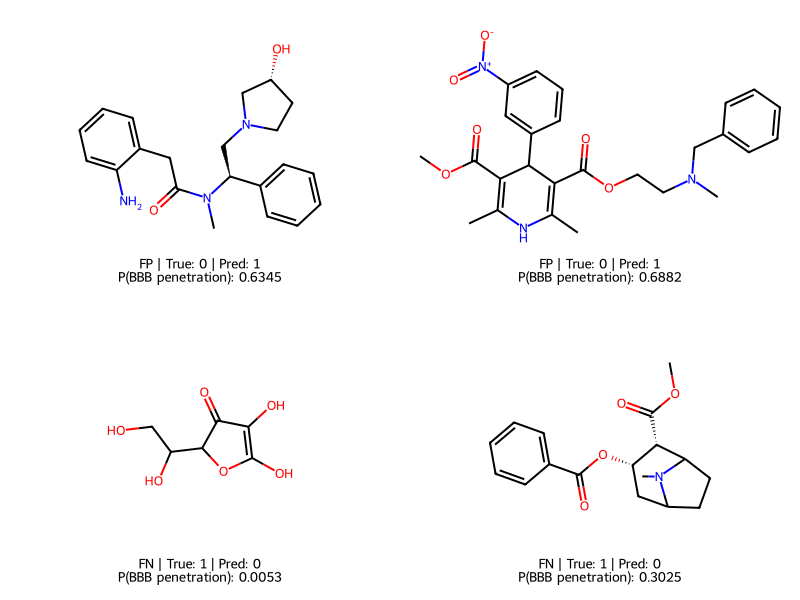

In [40]:
### Task G - Part 1 (Display two false-positive and two false-negative molecules from the scaffold test set.)

strategy = "Bemis-Murcko scaffold"
model = best_gnn_models[strategy]
threshold = best_gnn_thresholds[strategy]

model.eval()
test_probs = []

with torch.no_grad():
    for batch in gnn_test_loaders[strategy]:
        logits = model(batch)
        test_probs.extend(torch.sigmoid(logits).cpu().numpy())

test_probs = np.array(test_probs)
test_indices = np.array(scaffold_split["test"])
test_labels = labels[test_indices]
test_predictions = (test_probs >= threshold).astype(int)

false_positive_indices = np.where(
    (test_labels == 0) & (test_predictions == 1)
)[0]

false_negative_indices = np.where(
    (test_labels == 1) & (test_predictions == 0)
)[0]

print(f"False positives: {len(false_positive_indices)}")
print(f"False negatives: {len(false_negative_indices)}")

assert len(false_positive_indices) >= 2
assert len(false_negative_indices) >= 2

selected = [
    ("FP", i) for i in false_positive_indices[:2]
] + [
    ("FN", i) for i in false_negative_indices[:2]
]

molecules = []
legends = []

for error_type, position in selected:
    graph = cleaned_dataset[test_indices[position]]
    mol = Chem.MolFromSmiles(graph.smiles)

    molecules.append(mol)
    legends.append(
        f"{error_type} | True: {test_labels[position]} | "
        f"Pred: {test_predictions[position]}\n"
        f"P(BBB penetration): {test_probs[position]:.4f}"
    )

display(
    Draw.MolsToGridImage(
        molecules,
        molsPerRow=2,
        subImgSize=(400, 300),
        legends=legends,
        useSVG=False
    )
)

In [41]:
### Task G - Part 2 (Find the most similar scaffold-training molecule for each selected error using Morgan-fingerprint Tanimoto similarity.)

train_indices = np.array(scaffold_split["train"])
train_fps = fingerprints[train_indices].astype(bool)

similar_pairs = []

for error_type, position in selected:
    test_index = test_indices[position]
    test_fp = fingerprints[test_index].astype(bool)

    intersections = np.logical_and(train_fps, test_fp).sum(axis=1)
    unions = np.logical_or(train_fps, test_fp).sum(axis=1)

    similarities = np.divide(
        intersections,
        unions,
        out=np.zeros(len(train_indices), dtype=float),
        where=unions != 0
    )

    nearest_position = np.argmax(similarities)
    train_index = train_indices[nearest_position]

    similar_pairs.append({
        "error_type": error_type,
        "test_index": test_index,
        "train_index": train_index,
        "similarity": similarities[nearest_position],
        "test_position": position
    })

    error_number = sum(
        pair["error_type"] == error_type
        for pair in similar_pairs
    )

    print(
        f"{error_type} {error_number}: "
        f"Tanimoto similarity = {similarities[nearest_position]:.4f}, "
        f"Test label = {labels[test_index]}, "
        f"Training label = {labels[train_index]}"
    )

FP 1: Tanimoto similarity = 0.6545, Test label = 0, Training label = 1
FP 2: Tanimoto similarity = 0.6885, Test label = 0, Training label = 0
FN 1: Tanimoto similarity = 0.2000, Test label = 1, Training label = 0
FN 2: Tanimoto similarity = 0.4231, Test label = 1, Training label = 1


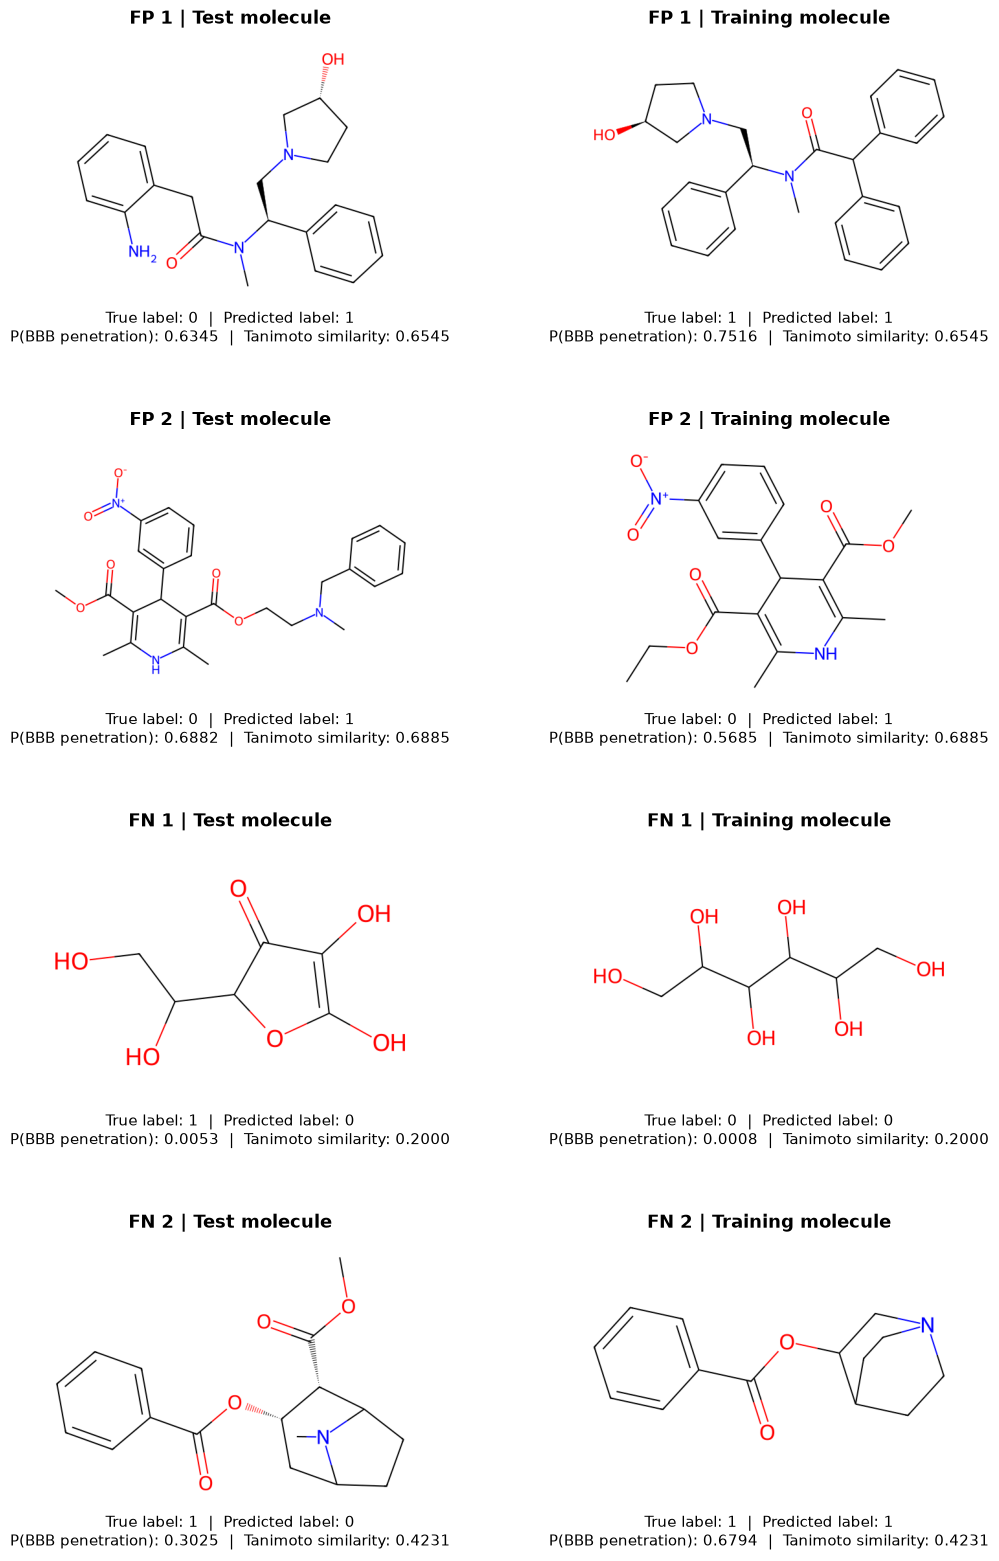

In [42]:
### Task G - Part 2 (Display each test–training molecule pair with readable labels, probabilities, and Tanimoto similarity.)

strategy = "Bemis-Murcko scaffold"
model = best_gnn_models[strategy]
threshold = best_gnn_thresholds[strategy]
model.eval()

train_graphs = [
    cleaned_dataset[pair["train_index"]]
    for pair in similar_pairs
]

train_batch = next(iter(DataLoader(
    train_graphs, batch_size=len(train_graphs), shuffle=False
)))

with torch.no_grad():
    train_probs = torch.sigmoid(model(train_batch)).cpu().numpy()

fig, axes = plt.subplots(4, 2, figsize=(13, 19))

error_counts = {"FP": 0, "FN": 0}

for i, pair in enumerate(similar_pairs):
    test_index = pair["test_index"]
    train_index = pair["train_index"]
    test_position = pair["test_position"]

    test_prob = test_probs[test_position]
    train_prob = train_probs[i]

    error_type = pair["error_type"]
    error_counts[error_type] += 1
    error_label = f"{error_type} {error_counts[error_type]}"

    for col, (source, index, prob) in enumerate([
        ("Test", test_index, test_prob),
        ("Training", train_index, train_prob)
    ]):
        ax = axes[i, col]

        mol = Chem.MolFromSmiles(cleaned_dataset[index].smiles)
        image = Draw.MolToImage(mol, size=(600, 400))

        ax.imshow(image)
        ax.axis("off")

        prediction = int(prob >= threshold)

        ax.set_title(
            f"{error_label} | {source} molecule",
            fontsize=13,
            fontweight="bold",
            pad=12
        )

        ax.text(
            0.5, -0.04,
            f"True label: {labels[index]}  |  "
            f"Predicted label: {prediction}\n"
            f"P(BBB penetration): {prob:.4f}  |  "
            f"Tanimoto similarity: {pair['similarity']:.4f}",
            transform=ax.transAxes,
            ha="center",
            va="top",
            fontsize=11
        )

plt.subplots_adjust(hspace=0.55, wspace=0.15)
plt.show()

### Task G - Part 2 (Discuss whether molecular similarity helps explain the errors or predicted probabilities.)

- **FP 1 (Tanimoto = 0.6545):** The test molecule has true label 0 but is predicted as class 1 with probability 0.6345. Its nearest training molecule has true label 1 and is also predicted as class 1 with probability 0.7516. Their similarity and matching predictions provide some context for the error, although they do not establish why the GNN made its prediction.

- **FP 2 (Tanimoto = 0.6885):** Both molecules have true label 0, but the GNN incorrectly predicts both as class 1, with probabilities 0.6882 and 0.5685. Their relatively high similarity and matching incorrect predictions show that similar molecules can share prediction errors.

- **FN 1 (Tanimoto = 0.2000):** The test molecule has true label 1 but receives a very low predicted probability of 0.0053. Its nearest training molecule has true label 0 and receives probability 0.0008. Both are predicted as class 0, but their low similarity provides little evidence to explain the test error.

- **FN 2 (Tanimoto = 0.4231):** Both molecules have true label 1, but the test molecule is incorrectly predicted as class 0 with probability 0.3025, while the training molecule is correctly predicted as class 1 with probability 0.6794. This shows that molecules sharing some fingerprint similarity can still receive different predictions.

Overall, Tanimoto similarity provides useful context for some errors, but it does not fully explain the GNN's predictions. Similarity alone cannot establish which molecular features influenced a prediction.

### Task G - Part 3 (Discuss limitations, causality, and clinical suitability.)

**Limitations:**

- **Label uncertainty:** The dataset labels may contain experimental errors or inconsistencies. I found 10 groups of duplicate molecules with conflicting labels, which suggests that some labels may be unreliable. Although I removed these conflicts, uncertainty may remain in the cleaned dataset.
- **Dataset size:** The cleaned dataset contains only 1,965 molecules. This limits the range of chemical structures the model learns from and may affect its ability to generalize to unfamiliar molecules.
- **Lack of external experimental validation:** I evaluated the models using held-out molecules from the same dataset, not an independent experimental dataset. Therefore, their performance on new molecules in real-world settings remains uncertain.

**Causality:** The models learn statistical relationships between molecular structures and BBB penetration labels. These relationships do not establish that particular molecular features cause BBB penetration.

**Clinical suitability:** Predicting BBB penetration alone does not demonstrate a molecule's safety, effectiveness, or suitability for clinical use. Further experimental and clinical validation would be required before making such conclusions.